<a href="https://colab.research.google.com/github/sharvi07/fake-job-detector/blob/main/notebooks/01_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd, numpy as np
import matplotlib.pyplot as plt

BASE = "/content/drive/MyDrive/fake-job-detector"
df = pd.read_csv(f"{BASE}/data/fake_job_postings.csv")
print(df.shape)
print(df["fraudulent"].value_counts())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(17880, 18)
fraudulent
0    17014
1      866
Name: count, dtype: int64


In [6]:
# 1. Class balance
print("Fraud %:", round(df["fraudulent"].mean() * 100, 2))

# 2. Duplicates (ignoring job_id)
print("Duplicates:", df.drop(columns="job_id").duplicated().sum())

# 3. Missing values: fraud rate when missing vs present
for col in ["company_profile", "salary_range", "requirements", "benefits", "department"]:
    miss = df[col].isna()
    print(f"{col}: fraud rate when missing = {df.loc[miss, 'fraudulent'].mean():.3f}, "
          f"when present = {df.loc[~miss, 'fraudulent'].mean():.3f}")

# 4. Binary flags vs fraud
print(df.groupby("fraudulent")[["telecommuting", "has_company_logo", "has_questions"]].mean())

# 5. Description length, real vs fake
df["desc_len"] = df["description"].fillna("").str.len()
print(df.groupby("fraudulent")["desc_len"].describe()[["mean", "50%", "max"]])

Fraud %: 4.84
Duplicates: 281
company_profile: fraud rate when missing = 0.177, when present = 0.019
salary_range: fraud rate when missing = 0.043, when present = 0.078
requirements: fraud rate when missing = 0.057, when present = 0.047
benefits: fraud rate when missing = 0.050, when present = 0.047
department: fraud rate when missing = 0.046, when present = 0.053
            telecommuting  has_company_logo  has_questions
fraudulent                                                
0                0.041319          0.819149       0.502057
1                0.073903          0.326790       0.288684
                   mean     50%      max
fraudulent                              
0           1238.691019  1034.0  22722.0
1           1162.697460   846.0   8578.0


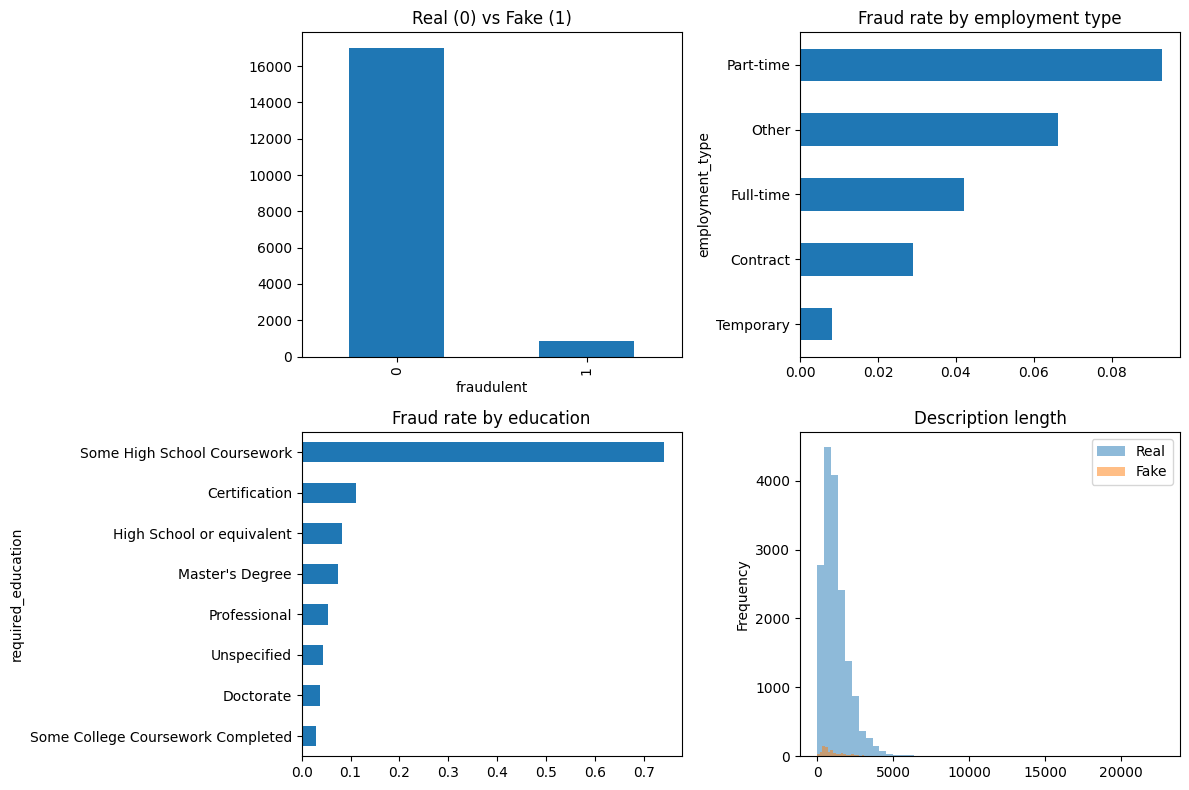

In [7]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))

# 1. Class balance
df["fraudulent"].value_counts().plot.bar(ax=ax[0,0], title="Real (0) vs Fake (1)")

# 2. Fraud rate by employment type
df.groupby("employment_type")["fraudulent"].mean().sort_values().plot.barh(ax=ax[0,1], title="Fraud rate by employment type")

# 3. Fraud rate by required education (top 8)
df.groupby("required_education")["fraudulent"].mean().sort_values().tail(8).plot.barh(ax=ax[1,0], title="Fraud rate by education")

# 4. Description length, real vs fake
df[df.fraudulent==0]["desc_len"].plot.hist(bins=50, alpha=0.5, ax=ax[1,1], label="Real")
df[df.fraudulent==1]["desc_len"].plot.hist(bins=50, alpha=0.5, ax=ax[1,1], label="Fake")
ax[1,1].set_title("Description length"); ax[1,1].legend()

plt.tight_layout()
plt.savefig(f"{BASE}/eda_charts.png", dpi=150)
plt.show()

In [8]:
df["country"] = df["location"].fillna("").str.split(",").str[0].str.strip()
top = df["country"].value_counts().head(10).index
print(df[df.country.isin(top)].groupby("country")["fraudulent"].agg(["mean", "count"]).sort_values("mean", ascending=False))

             mean  count
country                 
AU       0.186916    214
US       0.068506  10656
         0.054913    346
CA       0.026258    457
IN       0.014493    276
GB       0.009648   2384
PH       0.007576    132
DE       0.000000    383
GR       0.000000    940
NZ       0.000000    333


In [9]:
import re
from collections import Counter

def top_words(series, n=15):
    words = re.findall(r"[a-z]{4,}", " ".join(series.fillna("")).lower())
    return Counter(words).most_common(n)

print("FAKE:", top_words(df[df.fraudulent==1]["description"]))
print("REAL:", top_words(df[df.fraudulent==0]["description"]))

FAKE: [('with', 1767), ('work', 1052), ('will', 631), ('that', 626), ('this', 601), ('from', 599), ('team', 522), ('experience', 499), ('company', 491), ('time', 489), ('position', 477), ('management', 466), ('project', 454), ('customer', 453), ('service', 449)]
REAL: [('with', 39808), ('will', 22250), ('team', 18261), ('work', 14428), ('that', 14395), ('this', 11681), ('have', 11471), ('business', 10475), ('your', 10092), ('experience', 9981), ('company', 9722), ('customer', 9430), ('sales', 9327), ('looking', 8346), ('development', 7986)]


In [10]:
from sklearn.feature_extraction.text import CountVectorizer

text = df["description"].fillna("")
cv = CountVectorizer(stop_words="english", binary=True, min_df=30, token_pattern=r"[a-z]{4,}")
X = cv.fit_transform(text)

is_fake = df["fraudulent"].values == 1
fake_share = np.asarray(X[is_fake].mean(axis=0)).ravel()
real_share = np.asarray(X[~is_fake].mean(axis=0)).ravel()

res = pd.DataFrame({"word": cv.get_feature_names_out(),
                    "fake_share": fake_share, "real_share": real_share})
res["ratio"] = (res.fake_share + 0.001) / (res.real_share + 0.001)

print("MORE COMMON IN FAKE:")
print(res.sort_values("ratio", ascending=False).head(15))
print("MORE COMMON IN REAL:")
print(res.sort_values("ratio").head(15))

MORE COMMON IN FAKE:
               word  fake_share  real_share      ratio
2942   overviewaker    0.058891    0.000000  59.891455
1203           dfef    0.060046    0.000059  57.657370
1247    discoveries    0.060046    0.000059  57.657370
164            aker    0.055427    0.000000  56.427252
4592          wages    0.043880    0.000411  31.797566
1627          faces    0.050808    0.000647  31.465219
3067      petroleum    0.069284    0.002351  20.974025
4486       urgently    0.027714    0.000764  16.276858
4550         vessel    0.027714    0.000764  16.276858
4345           tour    0.024249    0.000705  14.806427
1038         cruise    0.024249    0.000705  14.806427
3893        shortly    0.026559    0.000882  14.646310
1096         decide    0.034642    0.001763  12.898574
3047           perm    0.024249    0.000999  12.629908
3079  photographers    0.024249    0.000999  12.629908
MORE COMMON IN REAL:
                     word  fake_share  real_share     ratio
290               

In [11]:
d = df.drop(columns="job_id")
dup_mask = d.duplicated()
print("Duplicates by class:")
print(df[dup_mask]["fraudulent"].value_counts())

print("Postings containing 'aker':")
print(df[df["description"].fillna("").str.contains("aker", case=False)]["fraudulent"].value_counts())

Duplicates by class:
fraudulent
0    271
1     10
Name: count, dtype: int64
Postings containing 'aker':
fraudulent
0    368
1     99
Name: count, dtype: int64


In [12]:
d = df.drop(columns="job_id")
dup_mask = d.duplicated()
print("Duplicates by class:")
print(df[dup_mask]["fraudulent"].value_counts())

print("Postings containing 'aker':")
print(df[df["description"].fillna("").str.contains("aker", case=False)]["fraudulent"].value_counts())

Duplicates by class:
fraudulent
0    271
1     10
Name: count, dtype: int64
Postings containing 'aker':
fraudulent
0    368
1     99
Name: count, dtype: int64


In [13]:
desc = df["description"].fillna("")
mask = desc.str.contains(r"\baker\b|overviewaker", case=False, regex=True)

print("Postings with the Aker template, by class:")
print(df[mask]["fraudulent"].value_counts())

print("\nSample fake posting:")
print(df[mask & (df.fraudulent==1)]["description"].iloc[0][:500])

Postings with the Aker template, by class:
fraudulent
1    52
Name: count, dtype: int64

Sample fake posting:
Corporate overviewAker Solutions is a global provider of products, systems and services to the oil and gas industry. Our engineering, design and technology bring discoveries into production and maximize recovery from each petroleum field. We employ approximately 28,000 people in about 30 countries. Go to #URL_0fa3f7c5e23a16de16a841e368006cae916884407d90b154dfef3976483a71ae# for more information on our business, people and values.We are looking for individuals who are prepared to take a position.


In [14]:
cols = ["company_profile", "salary_range", "requirements", "benefits", "department", "employment_type", "required_experience", "required_education", "industry", "function"]
df["n_missing"] = df[cols].isna().sum(axis=1)

print(df.groupby("n_missing")["fraudulent"].agg(["mean", "count"]))

               mean  count
n_missing                 
0          0.090433    763
1          0.043947   2321
2          0.034016   3322
3          0.024863   3097
4          0.025385   2206
5          0.058723   1175
6          0.057929   1381
7          0.069111   1418
8          0.101760   1307
9          0.037410    695
10         0.220513    195


In [15]:
notes = """# EDA Findings (Person 1)

## Dataset
- Shape: 17880 rows x 18 columns
- Real: 17014, Fake: 866 (4.84% fake, heavily imbalanced)
- 281 exact duplicates (ignoring job_id): 271 real, 10 fake. Drop them.

## Strong signals
- company_profile missing: fraud 17.7% vs 1.9% when present
- has_company_logo: 82% of real vs 33% of fake
- has_questions: 50% of real vs 29% of fake
- Country: AU 18.7% fraud (214 postings), US 6.9%, most others below 3%
- All 10 fields missing: 22% fraud. None missing: 9% fraud. Middle: about 2.5 to 4%
  (U-shaped, so use all_missing and none_missing flags, not a plain count)

## Weak signals
- telecommuting: 7.4% fake vs 4.1% real
- Description length: fake median 846 vs real 1034 characters
- salary_range, requirements, benefits, department: almost no difference

## Text issues for cleaning
- HTML tags were removed without leaving a space (words glued together). Add a space when removing tags.
- URLs appear as #URL_<hash># tokens. Remove them.
- One scam template (copy of Aker Solutions profile) appears in 52 postings, all fake (about 6% of fake class).
  Models may memorise it, so results may look better than they really are.
- Fake postings reuse normal job words (customer, service, management), so text is hard to separate.

## Recommended text columns to merge
title, company_profile, description, requirements, benefits

## Recommended extra features
missing company_profile, has_company_logo, has_questions, telecommuting,
country (top 10 + Other), text length, all_missing, none_missing
"""
with open(f"{BASE}/findings.md", "w") as f:
    f.write(notes)
print("saved")

saved
